In [1]:
# Librerías para manipulación, visualización y carga portable de datos.
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import os

# Usamos una ruta para Kaggle y otra para ejecución local en VS Code.
kaggle_path = '/kaggle/input/datasets/olistbr/brazilian-ecommerce'
local_path = 'data'

# Cargamos el dataset desde la ruta que exista en el entorno actual.
if os.path.exists(kaggle_path):
    base_path = kaggle_path
    print("Cargado desde el entorno de Kaggle")
elif os.path.exists(local_path):
    base_path = local_path
    print("Cargado desde el entorno local (VS Code)")
else:
    raise FileNotFoundError("No se encontro el archivo en ninguna de las rutas.")

# Funcion para carga dinamica
load_olist_dataset = lambda name: pd.read_csv(f"{base_path}/olist_{name}_dataset.csv")

# Carga de datasets
orders      = load_olist_dataset("orders")
items       = load_olist_dataset("order_items")
payments    = load_olist_dataset("order_payments")
reviews     = load_olist_dataset("order_reviews")
customers   = load_olist_dataset("customers")
products    = load_olist_dataset("products")
sellers     = load_olist_dataset("sellers")
geo         = load_olist_dataset("geolocation")
cat_tr      = pd.read_csv(f"{base_path}/product_category_name_translation.csv")

# Conversion de fechas a datetime
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
orders[date_cols] = orders[date_cols].apply(pd.to_datetime)

# Sanity check
for name, df in {"orders": orders, "items": items, "customers": customers}.items():
    print(name, df.shape, "| nulos:", df.isna().sum().sum())

Cargado desde el entorno local (VS Code)
orders (99441, 8) | nulos: 4908
items (112650, 7) | nulos: 0
customers (99441, 5) | nulos: 0


In [2]:
cust_orders = orders.merge(customers, on="customer_id")
freq = cust_orders.groupby("customer_unique_id")["order_id"].nunique()
print(freq.value_counts(normalize=True).head())

order_id
1    0.968812
2    0.028565
3    0.002112
4    0.000312
5    0.000083
Name: proportion, dtype: float64


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def build_preprocessor(num_cols, cat_cols):
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frecuency")),
        ("ohe",     OneHotEncoder(handle_unknown="ignore")),                
    ])
    
    return ColumnTransformer([
        ("nume", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ])

Rango: 2016-09-04 21:15:19 -> 2018-09-03 09:06:57


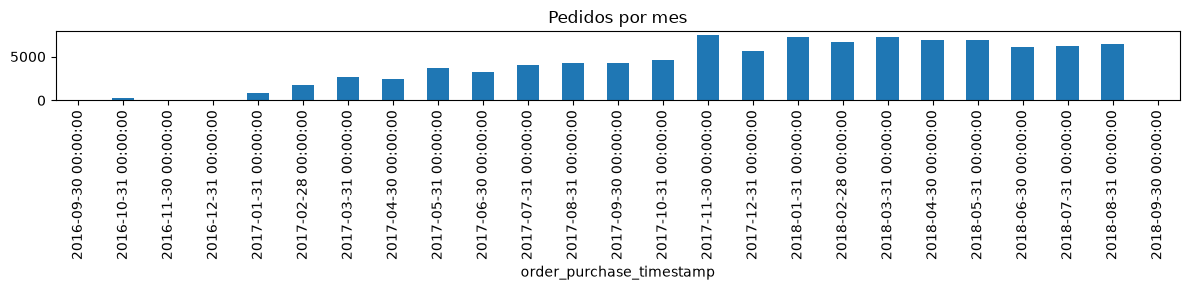

       cutoff  horizonte_d  clientes  recompra    tasa
0  2017-12-01           30     38289       114  0.0030
1  2017-12-01           90     38289       309  0.0081
2  2017-12-01          180     38289       522  0.0136
3  2018-01-01           30     43768       141  0.0032
4  2018-01-01           90     43768       324  0.0074
5  2018-01-01          180     43768       563  0.0129
6  2018-03-01           30     57143       141  0.0025
7  2018-03-01           90     57143       398  0.0070
8  2018-03-01          180     57143       676  0.0118


In [7]:
# 1) Tabla de pedidos con identidad real del cliente
oc = (orders.merge(customers[["customer_id", "customer_unique_id"]], on= "customer_id").query("order_status != 'canceled'"))

print("Rango:", oc.order_purchase_timestamp.min(), "->", oc.order_purchase_timestamp.max())

# 2) ¿Donde hay datos densos?
montly = oc.set_index("order_purchase_timestamp").resample("ME").size()
montly.plot(kind="bar", figsize=(12, 3), title="Pedidos por mes")

plt.tight_layout(); plt.show()

# 3) Explorar tasa de recompra según cutoff y horizonte
def repeat_rate(cutoff, horizon_days):
    cutoff = pd.Timestamp(cutoff)
    end = cutoff + pd.Timedelta(days=horizon_days)
    past    = oc[oc.order_purchase_timestamp < cutoff]
    future  = oc[(oc.order_purchase_timestamp >= cutoff) & (oc.order_purchase_timestamp < end)]
    base = past.customer_unique_id.unique()
    returned = np.intersect1d(base, future.customer_unique_id.unique())
    return len(base), len(returned), len(returned) / len(base)

rows = []
for cutoff in ["2017-12-01", "2018-01-01", "2018-03-01"]:
    for h in [30, 90, 180]:
        n, r, p = repeat_rate(cutoff, h)
        rows.append({"cutoff": cutoff, "horizonte_d": h, "clientes": n, "recompra": r, "tasa": round(p, 4)})
        
print(pd.DataFrame(rows))